# 01 · Data, contract identity and economic risk targets

**RQ1:** What is measured, and what historical information is available for it?
The first acceptance gate is a defensible target, not a favorable model score.
We use official SHFE copper settlements, actual contract identifiers and no
rolled continuous-price series. Raw files and individual outcomes remain local.

**Hypothesis:** effective same-contract history can be much shorter than a
nominal trailing window because contracts have finite lives. This matters when
comparing a pooled curve model with a current-contract covariance estimate.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from spde_covariance.empirical_research import load_research_evidence

evidence = load_research_evidence(Path("../experiments/results/shfe-research"))
print(evidence["protocol"]["status"])
print("Numerical source:", evidence["manifest"]["git_revision"])
print("Original baseline source:", evidence["protocol"]["baseline_source_revision"])
assert evidence["protocol"]["baseline_summary_sha256"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def table(rows, columns):
    print(" | ".join(columns))
    for row in rows:
        print(
            " | ".join(
                (
                    f"{row.get(c):.6g}" if isinstance(row.get(c), float) else str(row.get(c))
                    for c in columns
                )
            )
        )

exploratory development on inspected 2024–2025 data
Numerical source: a2f99054886b3154a311665cee7cacd8e6af483c
Original baseline source: d284718c0e465d39886500ab2d85904183266747


## Data and quality audit

Rows are one settlement per contract and session. The observed exchange calendar
contains all sessions found in the archives; no missing prices are filled.
Nonpositive volume or open interest disqualifies a quote from origin curve
reconstruction but does not delete its valid future settlement from P&L scoring.
Annual archives are retrospective and do not reconstruct original release vintages.

In [2]:
data = evidence["data"]
print("Sessions / rows / contracts:", data["sessions"], data["rows"], data["distinct_contracts"])
print("Session counts:", data["sessions_by_year"])
print("Quality:", json.dumps(data["quality"], indent=2))
print(data["vintage_scope"])
assert sum(data["sessions_by_year"].values()) == data["sessions"]

Sessions / rows / contracts: 969 11628 60
Session counts: {'2022': 242, '2023': 242, '2024': 242, '2025': 243}
Quality: {
  "settlement": {
    "missing": 0,
    "nonpositive": 0
  },
  "volume": {
    "missing": 0,
    "nonpositive": 10
  },
  "open_interest": {
    "missing": 0,
    "nonpositive": 2
  }
}
retrospective annual archives; original release vintages not reconstructed


## Risk target and units

At each origin choose eligible contracts nearest 90, 180 and 270 days, then hold
their **same IDs** to the next observed session. The coordinate is the 15th of
the contract month, not an actual expiry or a delivery-average map.

```math
Y_{i+1}=5\,a^\top(p_{i+1}^{\mathrm{same\ IDs}}-p_i),\qquad
v_i\approx\mathbb E[Y_{i+1}^2\mid\mathcal F_i].
```

The three holdings are outright $(1,0,0)$, spread $(1,-1,0)$ and butterfly
$(1,-2,1)$. Prices are CNY/tonne and P&L is CNY. With zero conditional mean this
second moment is a variance; otherwise a variance interpretation is an
additional assumption. These are next-session risks, not accumulated or annual returns.

lower_days | upper_days | rows | positive_volume_rows | positive_open_interest_rows
-10000 | 0 | 15 | 15 | 15
0 | 30 | 954 | 954 | 954
30 | 90 | 1910 | 1910 | 1910
90 | 180 | 2863 | 2863 | 2863
180 | 270 | 2862 | 2862 | 2862
270 | 365 | 3018 | 3008 | 3016
365 | 450 | 6 | 6 | 6
450 | 10000 | 0 | 0 | 0


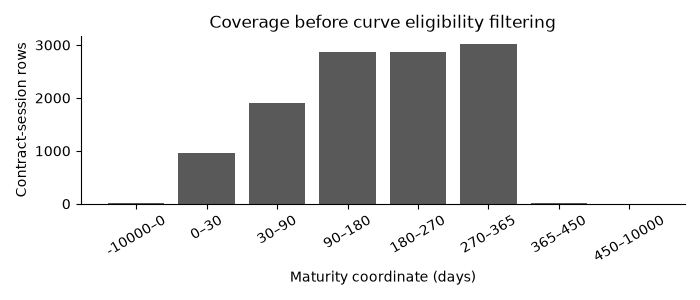

In [3]:
table(
    data["tenor_coverage"],
    ["lower_days", "upper_days", "rows", "positive_volume_rows", "positive_open_interest_rows"],
)
fig, ax = plt.subplots(figsize=(7, 3))
rows = data["tenor_coverage"]
ax.bar(np.arange(len(rows)), [r["rows"] for r in rows], color="0.35")
ax.set_xticks(
    np.arange(len(rows)), [f"{r['lower_days']}–{r['upper_days']}" for r in rows], rotation=30
)
ax.set(
    xlabel="Maturity coordinate (days)",
    ylabel="Contract-session rows",
    title="Coverage before curve eligibility filtering",
)
fig.tight_layout()
plt.show()

## Effective history for currently held contracts

Count only adjacent sessions where all three selected actual contracts have
settlements at both endpoints. Absent quotes do not create an artificial long
return. Counts below the declared minimum are unavailable, not zero covariance.
Exposure-specific baselines can use fewer legs; this three-leg audit is the
stricter common support used by the joint model and hedge experiment.

window | count | joint_count_quantiles | sufficient_count
63 | 484 | [49.0, 57.0, 62.0, 63.0, 63.0] | 484
126 | 484 | [49.0, 57.0, 62.0, 67.0, 77.0] | 484
252 | 484 | [49.0, 57.0, 62.0, 67.0, 77.0] | 484


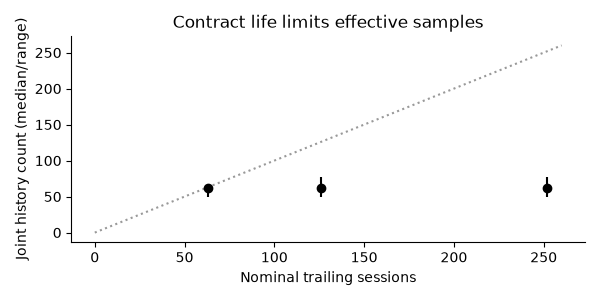

In [4]:
table(
    data["same_contract_history"], ["window", "count", "joint_count_quantiles", "sufficient_count"]
)
fig, ax = plt.subplots(figsize=(6, 3))
for row in data["same_contract_history"]:
    q = row["joint_count_quantiles"]
    if q:
        ax.errorbar(
            row["window"], q[2], yerr=[[q[2] - q[0]], [q[-1] - q[2]]], fmt="o", color="black"
        )
ax.plot([0, 260], [0, 260], linestyle=":", color="0.6")
ax.set(
    xlabel="Nominal trailing sessions",
    ylabel="Joint history count (median/range)",
    title="Contract life limits effective samples",
)
fig.tight_layout()
plt.show()

## Interpretation and next decision

Read the history counts before interpreting differences between nominal windows.
In this sample the nominal 252-session window contains only 49–77 joint changes
(median 62), the same range as the 126-session window.
This audit supports target definitions and reproducibility; it cannot certify
point-in-time data vintages, exchange execution, bid/ask costs or an exact
financial delivery map. Proceed to representation diagnostics before choosing
a more complex covariance model.

## Reproduction and research boundary

This notebook reads checksummed aggregate evidence, not raw exchange files.
The numerical algorithms are in `spde_covariance`; use the
[protocol](../docs/empirical-research-protocol.md) to rerun local calibration.
Execute this notebook with `uv run python scripts/check_notebook.py notebooks/01_data_and_risk_targets.ipynb`.

The original historical benchmark remains fixed. New analyses on the inspected
2024–2025 period are exploratory, even though forecast issuance is past-only.
No final untouched confirmation period, executable trading backtest or physical
forcing identification is claimed. See the [roadmap](../README.md).